In [39]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame

print(df.shape)
print(data.target_names)
print(df["target"].value_counts())
print(df.isnull().sum().sum())
df.head()

(569, 31)
['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64
0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [40]:
df["malignant"] = 1 - df["target"]
df = df.drop(columns=["target"])
df["malignant"].value_counts(normalize=True)

malignant
0    0.627417
1    0.372583
Name: proportion, dtype: float64

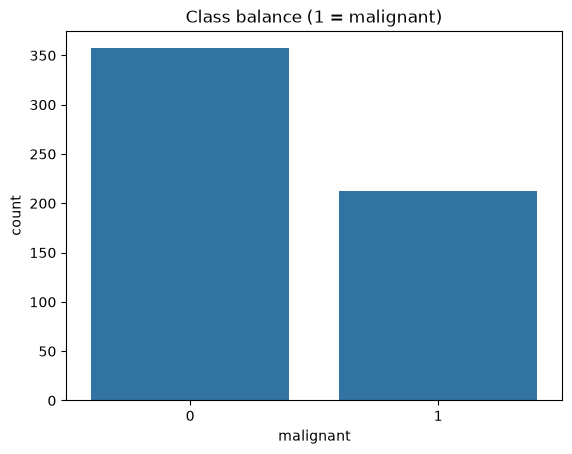

In [41]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("images", exist_ok=True)

sns.countplot(x="malignant", data=df)
plt.title("Class balance (1 = malignant)")
plt.savefig("images/class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

In [42]:
cols = ["mean radius", "mean texture", "mean area", "mean concavity"]
df.groupby("malignant")[cols].mean().T

malignant,0,1
mean radius,12.146524,17.462830
mean texture,17.914762,21.604906
mean area,462.790196,978.376415
mean concavity,0.046058,0.160775


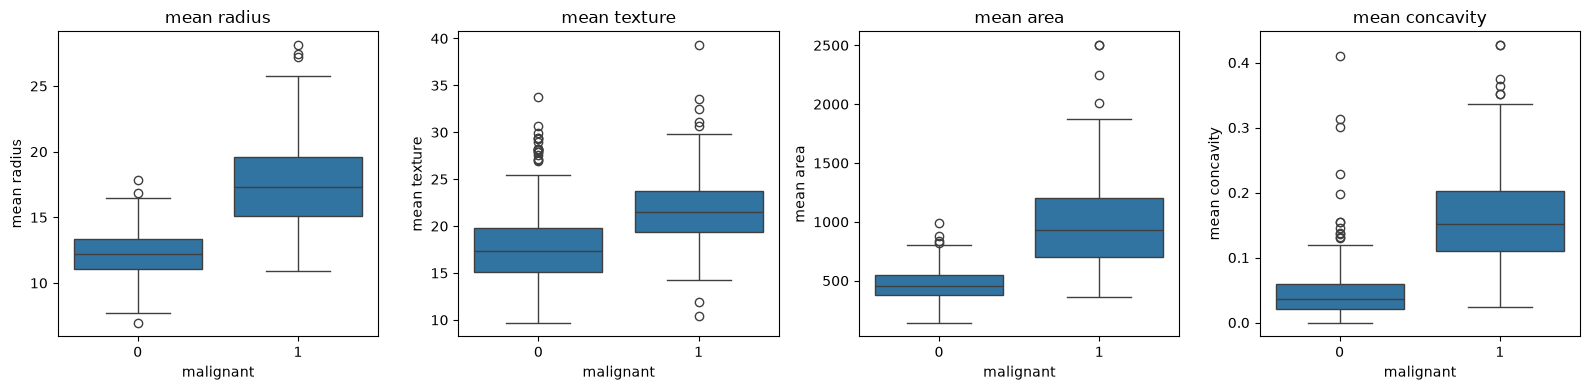

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(x="malignant", y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("images/boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

In [44]:
corr = df.corr()["malignant"].drop("malignant").sort_values(ascending=False)
print(corr.head(8))
print(corr.tail(5))

worst concave points    0.793566
worst perimeter         0.782914
mean concave points     0.776614
worst radius            0.776454
mean perimeter          0.742636
worst area              0.733825
mean radius             0.730029
mean area               0.708984
Name: malignant, dtype: float64
fractal dimension error    0.077972
symmetry error            -0.006522
texture error             -0.008303
mean fractal dimension    -0.012838
smoothness error          -0.067016
Name: malignant, dtype: float64


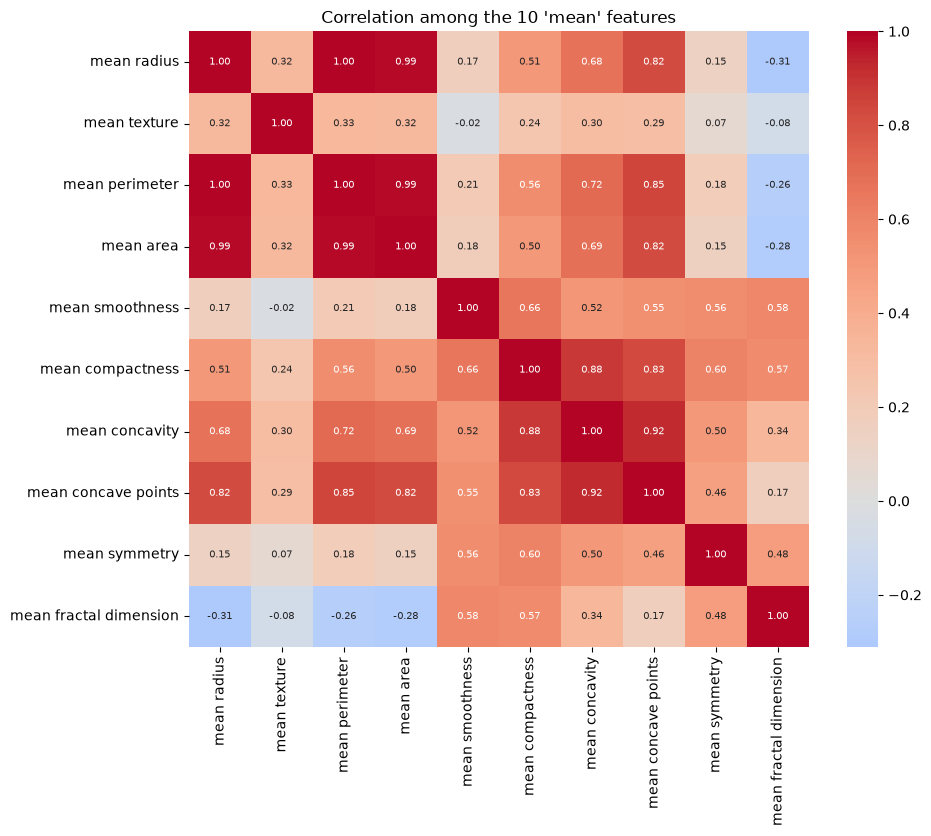

In [45]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.iloc[:, :10].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation among the 10 'mean' features")
plt.savefig("images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["malignant"])
y = df["malignant"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(455, 30) (114, 30)
0.37362637362637363 0.3684210526315789


In [47]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "SVM": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=42)),
    ]),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                             eval_metric="logloss", random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
SVM trained


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Random Forest trained
XGBoost trained


In [48]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

def evaluate(name, model):
    pred  = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Missed cancers (FN)": fn,
        "False alarms (FP)": fp,
    }

results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model")
results.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,Missed cancers (FN),False alarms (FP)
Model,,,,,,,
Logistic Regression,0.965,0.975,0.929,0.951,0.996,3,1
SVM,0.974,1.000,0.929,0.963,0.995,3,0
Random Forest,0.965,1.000,0.905,0.950,0.994,4,0
XGBoost,0.956,1.000,0.881,0.937,0.994,5,0


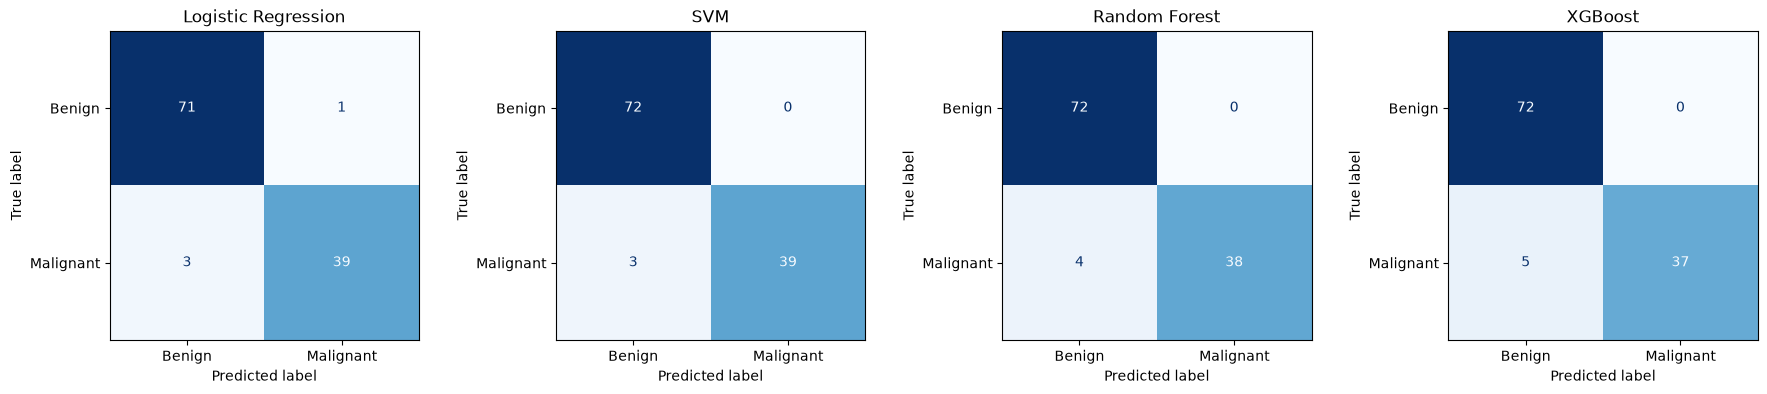

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test,
        display_labels=["Benign", "Malignant"],
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig("images/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

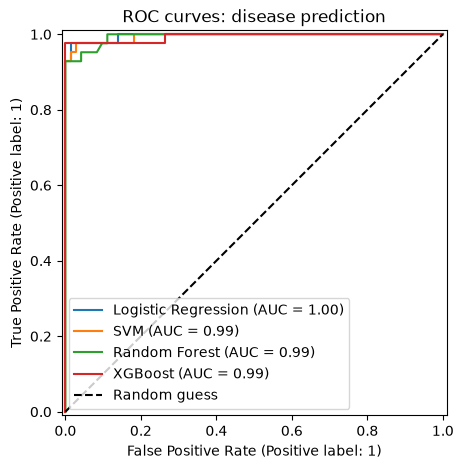

In [50]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
plt.title("ROC curves: disease prediction")
plt.savefig("images/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [51]:
from sklearn.metrics import classification_report

best = "Logistic Regression"   # change this to the model you think is best
print(classification_report(y_test, models[best].predict(X_test),
                            target_names=["Benign", "Malignant"]))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [52]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for k in scoring:
        row[k] = f"{s['test_' + k].mean():.3f} ± {s['test_' + k].std():.3f}"
    rows.append(row)

pd.DataFrame(rows).set_index("Model")

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Logistic Regression,0.974 ± 0.015,0.977 ± 0.028,0.953 ± 0.040,0.964 ± 0.021,0.996 ± 0.005
SVM,0.971 ± 0.005,0.977 ± 0.021,0.947 ± 0.034,0.961 ± 0.008,0.995 ± 0.005
Random Forest,0.963 ± 0.015,0.964 ± 0.011,0.935 ± 0.039,0.949 ± 0.021,0.989 ± 0.007
XGBoost,0.971 ± 0.011,0.970 ± 0.018,0.953 ± 0.024,0.961 ± 0.015,0.994 ± 0.004


In [53]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.001],
}

grid = GridSearchCV(models["SVM"], param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(round(grid.best_score_, 3))

{'model__C': 10, 'model__gamma': 'scale'}
0.967


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [54]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

final = grid.best_estimator_
proba_cv = cross_val_predict(final, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]

for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = (proba_cv >= t).astype(int)
    print(t,
          round(precision_score(y_train, pred), 3),
          round(recall_score(y_train, pred), 3),
          round(f1_score(y_train, pred), 3))

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239

0.2 0.912 0.971 0.94
0.3 0.927 0.971 0.948
0.4 0.948 0.965 0.956
0.5 0.97 0.965 0.968
0.6 0.976 0.965 0.97


In [55]:
threshold = 0.5   # replace with the value you chose above

proba_test = final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= threshold).astype(int)

print("Precision:", round(precision_score(y_test, pred_test), 3))
print("Recall:   ", round(recall_score(y_test, pred_test), 3))
print("F1:       ", round(f1_score(y_test, pred_test), 3))

Precision: 1.0
Recall:    0.929
F1:        0.963


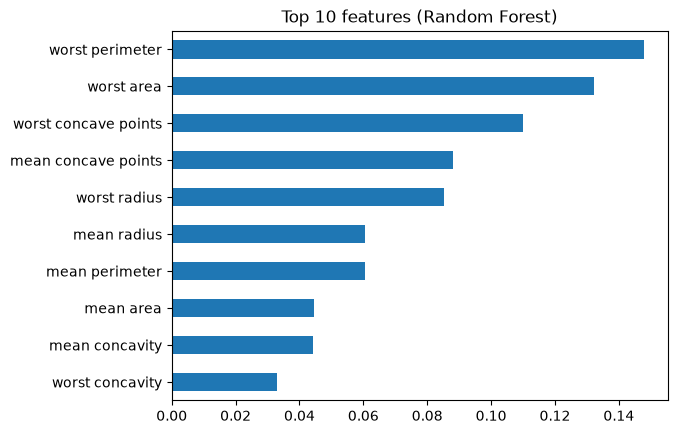

compactness error         -0.906925
fractal dimension error   -0.593876
mean compactness          -0.439546
texture error             -0.407611
symmetry error            -0.330658
dtype: float64
worst concavity        0.911406
mean concave points    0.952813
worst symmetry         1.061264
radius error           1.233325
worst texture          1.434093
dtype: float64


In [56]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

ax = imp.head(10).plot(kind="barh")
ax.invert_yaxis()
plt.title("Top 10 features (Random Forest)")
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

lr = models["Logistic Regression"].named_steps["model"]
coefs = pd.Series(lr.coef_[0], index=X.columns).sort_values()
print(coefs.head(5))
print(coefs.tail(5))

In [57]:
import joblib
joblib.dump(final, "disease_model.joblib")
loaded = joblib.load("disease_model.joblib")
loaded.predict_proba(X_test.iloc[[0]])

array([[9.99808652e-01, 1.91347681e-04]])

In [59]:
import os
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

res = results.round(3)
table = "\n".join(
    ["| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Missed cancers (FN) | False alarms (FP) |",
     "|---|---|---|---|---|---|---|---|"]
    + [f"| {n} | {r['Accuracy']} | {r['Precision']} | {r['Recall']} | {r['F1']} | {r['ROC-AUC']} | {int(r['Missed cancers (FN)'])} | {int(r['False alarms (FP)'])} |"
       for n, r in res.iterrows()])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cvres = {}
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=["recall", "f1", "roc_auc"])
    cvres[name] = {k: (s[f"test_{k}"].mean(), s[f"test_{k}"].std()) for k in ["recall", "f1", "roc_auc"]}
cv_table = "\n".join(
    ["| Model | Recall | F1 | ROC-AUC |", "|---|---|---|---|"]
    + [f"| {n} | " + " | ".join(f"{v[k][0]:.3f} ± {v[k][1]:.3f}" for k in ["recall", "f1", "roc_auc"]) + " |"
       for n, v in cvres.items()])
top_name = max(cvres, key=lambda n: cvres[n]["roc_auc"][0])
top_mean, top_std = cvres[top_name]["roc_auc"]
tied = [n for n, v in cvres.items() if v["roc_auc"][0] >= top_mean - top_std]

proba_test = final.predict_proba(X_test)[:, 1]
pred = (proba_test >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns)
top = ", ".join(imp.sort_values(ascending=False).head(5).index)

imgs = "\n".join(f"![{t}](images/{f})" for t, f in
    [("Class balance", "class_balance.png"), ("ROC curves", "roc_curves.png"),
     ("Confusion matrices", "confusion_matrices.png"),
     ("Feature importance", "feature_importance.png")] if os.path.exists(f"images/{f}"))

readme = f"""# Task 4: Disease Prediction from Medical Data

## Objective
Predict whether a breast tumour is malignant or benign from cell-nucleus measurements. The positive class is malignant (1), because missing a cancer is the costly mistake.

## Dataset
Breast Cancer Wisconsin (Diagnostic), UCI ML Repository, loaded with scikit-learn.
- {len(df)} patients, {X.shape[1]} numeric features, no missing values
- {df['malignant'].sum()} malignant ({df['malignant'].mean() * 100:.1f}%) and {(1 - df['malignant']).sum()} benign

## Approach
1. EDA: class balance, boxplots, correlations
2. Stratified 80/20 split ({len(X_train)} train / {len(X_test)} test)
3. Scaling inside a Pipeline for Logistic Regression and SVM
4. Models: Logistic Regression, SVM, Random Forest, XGBoost
5. Evaluation: Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrices
6. 5-fold cross-validation and SVM tuning with GridSearchCV
7. Threshold chosen on training data only, then one final test

## Results (test set, default threshold)
{table}

## Cross-validation (training data, mean ± std)
{cv_table}

Highest mean ROC-AUC: **{top_name}** ({top_mean:.3f}). Models within one standard deviation of it, which the data cannot separate: {", ".join(tied)}.

## Final model
{type(final.named_steps['model']).__name__} tuned with GridSearchCV, best parameters {grid.best_params_}, threshold {threshold}.
Final test: Precision {precision_score(y_test, pred):.3f}, Recall {recall_score(y_test, pred):.3f}, F1 {f1_score(y_test, pred):.3f}, ROC-AUC {roc_auc_score(y_test, proba_test):.3f}.
It missed {fn} of {fn + tp} malignant cases and raised {fp} false alarms on {tn + fp} benign cases.

Top 5 features (Random Forest): {top}.

{imgs}

## Limitations
- Only {len(df)} patients, so test metrics are noisy and small differences between models are not meaningful.
- The dataset is clean and curated; real hospital data would be harder.
- A learning project, not a diagnostic tool.

## How to run
Open `disease_prediction.ipynb` and click Run All.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)
print(readme)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239

# Task 4: Disease Prediction from Medical Data

## Objective
Predict whether a breast tumour is malignant or benign from cell-nucleus measurements. The positive class is malignant (1), because missing a cancer is the costly mistake.

## Dataset
Breast Cancer Wisconsin (Diagnostic), UCI ML Repository, loaded with scikit-learn.
- 569 patients, 30 numeric features, no missing values
- 212 malignant (37.3%) and 357 benign

## Approach
1. EDA: class balance, boxplots, correlations
2. Stratified 80/20 split (455 train / 114 test)
3. Scaling inside a Pipeline for Logistic Regression and SVM
4. Models: Logistic Regression, SVM, Random Forest, XGBoost
5. Evaluation: Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrices
6. 5-fold cross-validation and SVM tuning with GridSearchCV
7. Threshold chosen on training data only, then one final test

## Results (test set, default threshold)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Missed cancers (FN) | False alarms (FP) |
|---|---|